In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

All libraries imported successfully!
Pandas version: 3.0.3
NumPy version: 2.4.6
Scikit-learn version: 1.9.0


In [7]:
import os

folder_path = r"C:\Users\saksh\Downloads\online+retail"

files = os.listdir(folder_path)

for file in files:
    print(file)

Online Retail.xlsx


In [13]:
import pandas as pd

file_path = r"C:\Users\saksh\Downloads\online+retail\Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [14]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [15]:
df.shape

(541909, 8)

In [16]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [17]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (541909, 8)

Column Names:
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [18]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [19]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64


In [20]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 5268


In [21]:
df[df.duplicated()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [22]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (536641, 8)


In [23]:
print("Negative quantities:",
      (df["Quantity"] < 0).sum())

print("Zero quantities:",
      (df["Quantity"] == 0).sum())

Negative quantities: 10587
Zero quantities: 0


In [24]:
df[df["Quantity"] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [25]:
print("Negative prices:",
      (df["UnitPrice"] < 0).sum())

print("Zero prices:",
      (df["UnitPrice"] == 0).sum())

Negative prices: 2
Zero prices: 2510


In [26]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

df[["Quantity", "UnitPrice", "Revenue"]].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [27]:
print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTotal revenue:")
print(df["Revenue"].sum())

Final dataset shape: (536641, 9)

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
Revenue             0
dtype: int64

Duplicate rows:
0

Total revenue:
9726006.954


In [28]:
# Keep a backup before further cleaning
df_backup = df.copy()

print("Backup created successfully!")
# Create a separate working dataset
df_clean = df.copy()

# Remove transactions without CustomerID
df_clean = df_clean.dropna(subset=["CustomerID"])

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep only positive quantities
df_clean = df_clean[df_clean["Quantity"] > 0]

# Keep only positive prices
df_clean = df_clean[df_clean["UnitPrice"] > 0]

# Reset row numbering
df_clean = df_clean.reset_index(drop=True)

print("Customer analysis dataset created!")
print("New shape:", df_clean.shape)

Backup created successfully!
Customer analysis dataset created!
New shape: (392692, 9)


In [29]:
print("Missing Customer IDs:",
      df_clean["CustomerID"].isnull().sum())

print("Negative quantities:",
      (df_clean["Quantity"] < 0).sum())

print("Non-positive prices:",
      (df_clean["UnitPrice"] <= 0).sum())

print("Duplicate rows:",
      df_clean.duplicated().sum())

print("Total cleaned revenue:",
      df_clean["Revenue"].sum())

Missing Customer IDs: 0
Negative quantities: 0
Non-positive prices: 0
Duplicate rows: 0
Total cleaned revenue: 8887208.894000001


In [30]:
# Create working copy
df_clean = df_backup.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove missing CustomerIDs
df_clean = df_clean.dropna(subset=["CustomerID"])

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep positive quantities
df_clean = df_clean[df_clean["Quantity"] > 0]

# Keep positive prices
df_clean = df_clean[df_clean["UnitPrice"] > 0]

# Calculate revenue
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Convert CustomerID to string
df_clean["CustomerID"] = (
    df_clean["CustomerID"].astype("int64").astype(str)
)

df_clean.reset_index(drop=True, inplace=True)

print("Cleaned dataset:", df_clean.shape)
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Total revenue:", df_clean["Revenue"].sum())

Cleaned dataset: (392692, 9)
Unique customers: 4338
Total revenue: 8887208.894000001


In [31]:
# Total unique customers
total_customers = df_clean["CustomerID"].nunique()

# Total unique invoices
total_invoices = df_clean["InvoiceNo"].nunique()

# Total products
total_products = df_clean["StockCode"].nunique()

# Total countries
total_countries = df_clean["Country"].nunique()

# First and last purchase date
first_date = df_clean["InvoiceDate"].min()
last_date = df_clean["InvoiceDate"].max()

# Display results
print("BUSINESS OVERVIEW")
print("-------------------------")

print("Total Customers:", total_customers)
print("Total Invoices:", total_invoices)
print("Total Products:", total_products)
print("Total Countries:", total_countries)

print("First Purchase Date:", first_date)
print("Last Purchase Date:", last_date)

print("Total Revenue: £", round(df_clean["Revenue"].sum(), 2))

BUSINESS OVERVIEW
-------------------------
Total Customers: 4338
Total Invoices: 18532
Total Products: 3665
Total Countries: 37
First Purchase Date: 2010-12-01 08:26:00
Last Purchase Date: 2011-12-09 12:50:00
Total Revenue: £ 8887208.89


In [32]:
df_clean["Month"] = (
    df_clean["InvoiceDate"].dt.to_period("M").astype(str)
)

df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12


In [33]:
monthly_revenue = (
    df_clean.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

monthly_revenue

,Month,Revenue
0,2010-12,570422.730
1,2011-01,568101.310
2,2011-02,446084.920
3,2011-03,594081.760
4,2011-04,468374.331
5,2011-05,677355.150
6,2011-06,660046.050
7,2011-07,598962.901
8,2011-08,644051.040
9,2011-09,950690.202


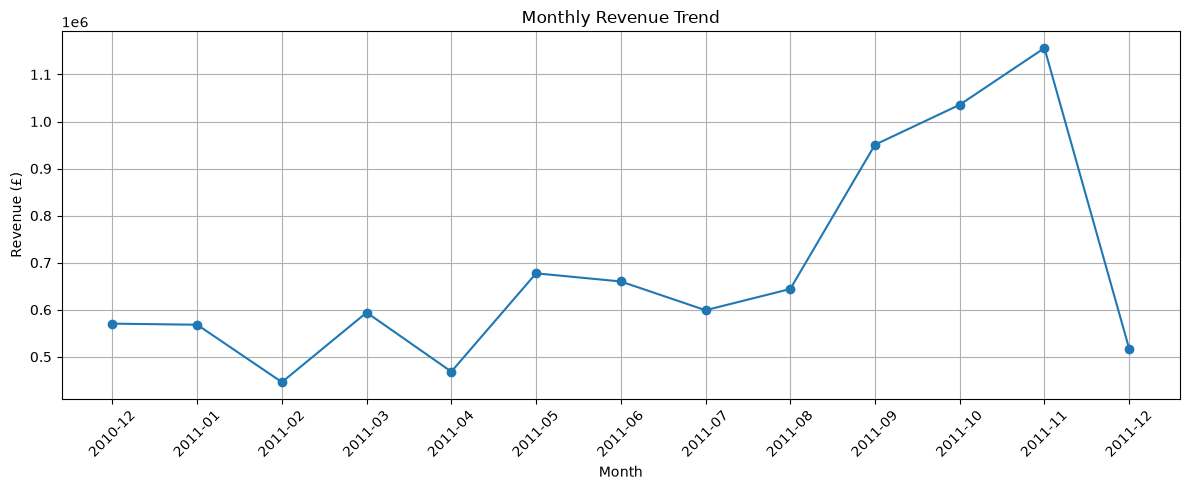

In [34]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["Month"],
    monthly_revenue["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [35]:
country_revenue = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_revenue

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

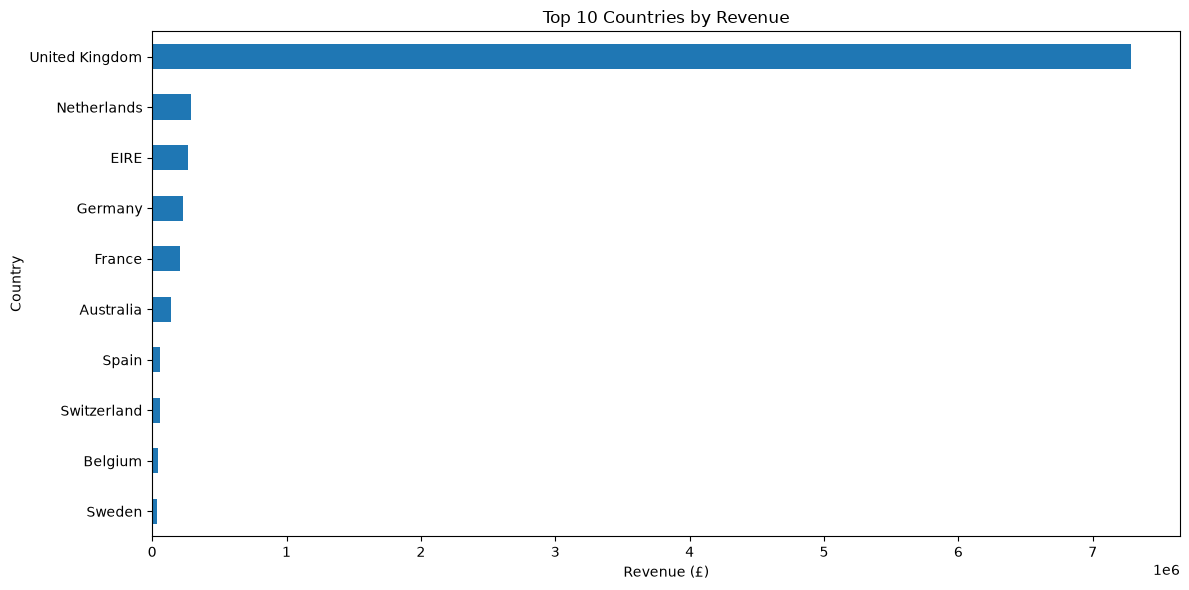

In [36]:
plt.figure(figsize=(12, 6))

country_revenue.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [37]:
top_products = (
    df_clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: Revenue, dtype: float64

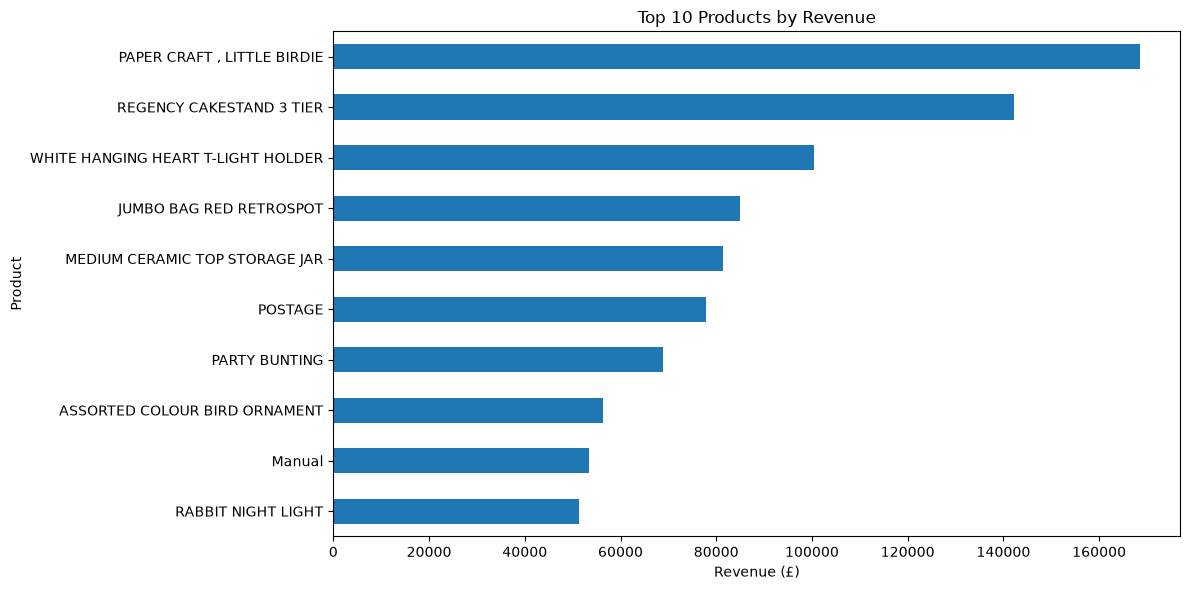

In [38]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [39]:
# Find the latest transaction date
latest_date = df_clean["InvoiceDate"].max()

# Calculate a reference date (one day after last transaction)
snapshot_date = latest_date + pd.Timedelta(days=1)

print("Latest transaction:", latest_date)
print("Reference date:", snapshot_date)

Latest transaction: 2011-12-09 12:50:00
Reference date: 2011-12-10 12:50:00


In [40]:
rfm = df_clean.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "Revenue": "sum"
})

# Rename columns
rfm.rename(columns={
    "InvoiceDate": "Recency",
    "InvoiceNo": "Frequency",
    "Revenue": "Monetary"
}, inplace=True)

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [41]:
print("RFM dataset shape:", rfm.shape)

print("\nRFM summary:")
print(rfm.describe())

print("\nFirst 10 customers:")
print(rfm.head(10))

RFM dataset shape: (4338, 3)

RFM summary:
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.000000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000

First 10 customers:
            Recency  Frequency  Monetary
CustomerID                              
12346           326          1  77183.60
12347             2          7   4310.00
12348            75          4   1797.24
12349            19          1   1757.55
12350           310          1    334.40
12352            36          8   2506.04
12353           204          1     89.00
12354           232          1   1079.40
12355           214          1    459.40
12356            23          3   2811.43


In [42]:
# Assign RFM scores

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

# Convert scores into integers
rfm["R_Score"] = rfm["R_Score"].astype(int)
rfm["F_Score"] = rfm["F_Score"].astype(int)
rfm["M_Score"] = rfm["M_Score"].astype(int)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346,326,1,77183.60,1,1,5
12347,2,7,4310.00,5,5,5
12348,75,4,1797.24,2,4,4
12349,19,1,1757.55,4,1,4
12350,310,1,334.40,1,1,2
12352,36,8,2506.04,3,5,5
12353,204,1,89.00,1,1,1
12354,232,1,1079.40,1,1,4
12355,214,1,459.40,1,1,2


In [43]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

rfm["RFM_Total"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
CustomerID,,,,,,,,
12346,326,1,77183.60,1,1,5,115,7
12347,2,7,4310.00,5,5,5,555,15
12348,75,4,1797.24,2,4,4,244,10
12349,19,1,1757.55,4,1,4,414,9
12350,310,1,334.40,1,1,2,112,4
12352,36,8,2506.04,3,5,5,355,13
12353,204,1,89.00,1,1,1,111,3
12354,232,1,1079.40,1,1,4,114,6
12355,214,1,459.40,1,1,2,112,4


In [44]:
def customer_segment(row):

    if row["RFM_Score"] == "555":
        return "Champions"

    elif row["R_Score"] >= 4 and row["F_Score"] >= 4:
        return "Loyal Customers"

    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "Recent Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"

    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Lost Customers"

    else:
        return "Potential Loyalists"


rfm["Segment"] = rfm.apply(customer_segment, axis=1)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,Segment
CustomerID,,,,,,,,,
12346,326,1,77183.60,1,1,5,115,7,Lost Customers
12347,2,7,4310.00,5,5,5,555,15,Champions
12348,75,4,1797.24,2,4,4,244,10,At Risk
12349,19,1,1757.55,4,1,4,414,9,Recent Customers
12350,310,1,334.40,1,1,2,112,4,Lost Customers
12352,36,8,2506.04,3,5,5,355,13,Potential Loyalists
12353,204,1,89.00,1,1,1,111,3,Lost Customers
12354,232,1,1079.40,1,1,4,114,6,Lost Customers
12355,214,1,459.40,1,1,2,112,4,Lost Customers


In [45]:
segment_counts = rfm["Segment"].value_counts()

print(segment_counts)

Segment
Potential Loyalists    1172
Lost Customers         1074
Loyal Customers         774
At Risk                 661
Champions               347
Recent Customers        310
Name: count, dtype: int64


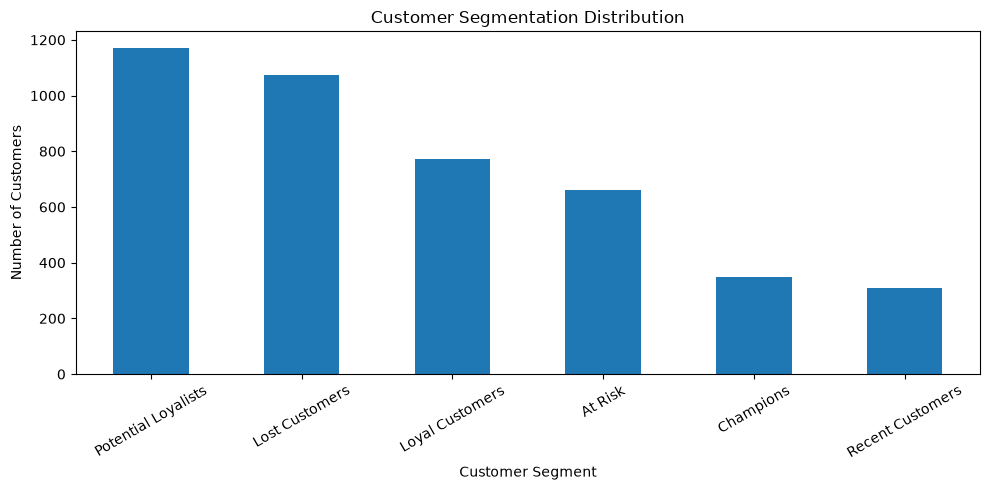

In [46]:
plt.figure(figsize=(10, 5))

segment_counts.plot(kind="bar")

plt.title("Customer Segmentation Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [47]:
# Define prediction date
snapshot_date = pd.Timestamp("2011-09-01")

# Define end of 90-day observation window
future_end_date = snapshot_date + pd.Timedelta(days=90)

# Historical data: before September 1
historical_data = df_clean[
    df_clean["InvoiceDate"] < snapshot_date
].copy()

# Future data: September 1 to November 29
future_data = df_clean[
    (df_clean["InvoiceDate"] >= snapshot_date) &
    (df_clean["InvoiceDate"] < future_end_date)
].copy()

print("Prediction Date:", snapshot_date)
print("Future Window Ends:", future_end_date)

print("Historical Records:", historical_data.shape)
print("Future Records:", future_data.shape)

Prediction Date: 2011-09-01 00:00:00
Future Window Ends: 2011-11-30 00:00:00
Historical Records: (224036, 10)
Future Records: (149526, 10)


In [48]:
# Calculate historical customer behaviour
customer_features = historical_data.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "Revenue": "sum"
})

# Rename columns
customer_features.rename(columns={
    "InvoiceDate": "Recency",
    "InvoiceNo": "Frequency",
    "Revenue": "Monetary"
}, inplace=True)

customer_features.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,225,1,77183.60
12347,29,5,2790.86
12348,148,3,1487.24
12350,210,1,334.40
12352,162,5,1561.81


In [49]:
# Count future invoices for each customer
future_purchases = (
    future_data.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

# Add future purchase count to customer features
customer_features["Future_Purchases"] = (
    future_purchases.reindex(customer_features.index)
    .fillna(0)
)

# Create churn label
# 1 = No purchase in the next 90 days
# 0 = At least one purchase in the next 90 days

customer_features["Churn"] = (
    customer_features["Future_Purchases"] == 0
).astype(int)

customer_features.head(10)

,Recency,Frequency,Monetary,Future_Purchases,Churn
CustomerID,,,,,
12346,225,1,77183.60,0.0,1
12347,29,5,2790.86,1.0,0
12348,148,3,1487.24,1.0,0
12350,210,1,334.40,0.0,1
12352,162,5,1561.81,3.0,0
12353,104,1,89.00,0.0,1
12354,132,1,1079.40,0.0,1
12355,114,1,459.40,0.0,1
12356,145,2,2753.08,1.0,0


In [50]:
print("Total customers:", len(customer_features))

print("\nChurn distribution:")
print(customer_features["Churn"].value_counts())

print("\nChurn percentage:")
print(
    customer_features["Churn"]
    .value_counts(normalize=True) * 100
)

Total customers: 3317

Churn distribution:
Churn
0    1864
1    1453
Name: count, dtype: int64

Churn percentage:
Churn
0    56.195357
1    43.804643
Name: proportion, dtype: float64


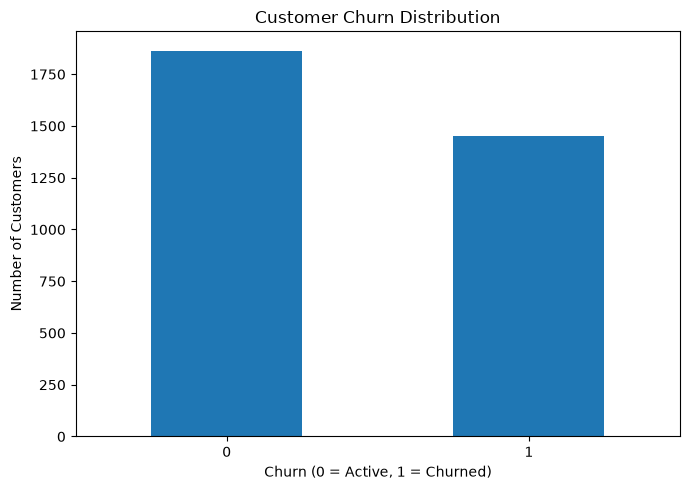

In [51]:
customer_features["Churn"].value_counts().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = Active, 1 = Churned)")
plt.ylabel("Number of Customers")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [52]:
# Input features
X = customer_features[
    ["Recency", "Frequency", "Monetary"]
]

# Target variable
y = customer_features["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (3317, 3)
Target shape: (3317,)

Feature columns:
['Recency', 'Frequency', 'Monetary']


In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (2653, 3)
Testing features: (664, 3)
Training target: (2653,)
Testing target: (664,)


In [54]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression pipeline
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [55]:
# Predict churn on testing data
lr_predictions = lr_model.predict(X_test)

# Predict churn probabilities
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(lr_predictions[:10])

First 10 actual values:
[1 1 0 0 0 0 0 0 0 0]

First 10 predicted values:
[0 1 1 0 0 0 1 1 1 0]


In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")

print("Accuracy:", accuracy_score(y_test, lr_predictions))
print("Precision:", precision_score(y_test, lr_predictions))
print("Recall:", recall_score(y_test, lr_predictions))
print("F1 Score:", f1_score(y_test, lr_predictions))

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.6566265060240963
Precision: 0.6113074204946997
Recall: 0.5945017182130584
F1 Score: 0.6027874564459931

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.71      0.70       373
           1       0.61      0.59      0.60       291

    accuracy                           0.66       664
   macro avg       0.65      0.65      0.65       664
weighted avg       0.66      0.66      0.66       664



In [57]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")
rf_predictions = rf_model.predict(X_test)

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("First 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(rf_predictions[:10])
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Random Forest Results")

print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions))
print("Recall:", recall_score(y_test, rf_predictions))
print("F1 Score:", f1_score(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, rf_predictions)
    ],
    "Recall": [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, rf_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, rf_predictions)
    ]
})

model_comparison

Random Forest model trained successfully!
First 10 actual values:
[1 1 0 0 0 0 0 0 0 0]

First 10 predicted values:
[0 0 1 0 0 0 1 0 1 0]
Random Forest Results
Accuracy: 0.6189759036144579
Precision: 0.5678571428571428
Recall: 0.5463917525773195
F1 Score: 0.5569176882661997

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.68      0.67       373
           1       0.57      0.55      0.56       291

    accuracy                           0.62       664
   macro avg       0.61      0.61      0.61       664
weighted avg       0.62      0.62      0.62       664



,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.656627,0.611307,0.594502,0.602787
1,Random Forest,0.618976,0.567857,0.546392,0.556918


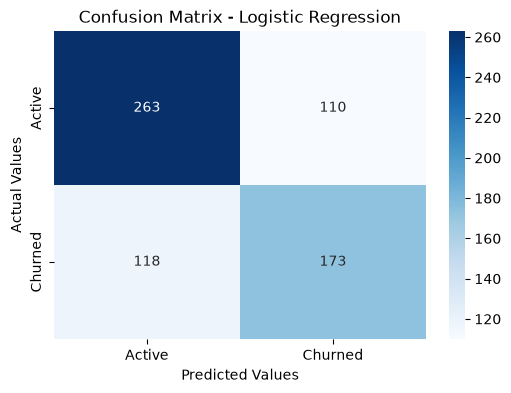

In [58]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Active", "Churned"],
    yticklabels=["Active", "Churned"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

In [59]:
lr_coefficients = lr_model.named_steps["model"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr_coefficients
})

feature_importance["Absolute Importance"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

feature_importance

,Feature,Coefficient,Absolute Importance
1,Frequency,-1.873995,1.873995
0,Recency,0.360026,0.360026
2,Monetary,0.000630,0.000630


In [60]:
clv = df_clean.groupby("CustomerID").agg({
    "InvoiceNo": "nunique",
    "Quantity": "sum",
    "Revenue": "sum"
})

clv.rename(columns={
    "InvoiceNo": "Total_Orders",
    "Quantity": "Total_Quantity",
    "Revenue": "Customer_Lifetime_Value"
}, inplace=True)

clv.head()

,Total_Orders,Total_Quantity,Customer_Lifetime_Value
CustomerID,,,
12346,1,74215,77183.60
12347,7,2458,4310.00
12348,4,2341,1797.24
12349,1,631,1757.55
12350,1,197,334.40


In [61]:
# Calculate the 25th and 75th percentile
low_threshold = clv["Customer_Lifetime_Value"].quantile(0.25)
high_threshold = clv["Customer_Lifetime_Value"].quantile(0.75)

# Create customer value segments
def assign_value_segment(value):
    if value >= high_threshold:
        return "High Value"
    elif value >= low_threshold:
        return "Medium Value"
    else:
        return "Low Value"

clv["Value_Segment"] = clv["Customer_Lifetime_Value"].apply(
    assign_value_segment
)

clv.head(10)

,Total_Orders,Total_Quantity,Customer_Lifetime_Value,Value_Segment
CustomerID,,,,
12346,1,74215,77183.60,High Value
12347,7,2458,4310.00,High Value
12348,4,2341,1797.24,High Value
12349,1,631,1757.55,High Value
12350,1,197,334.40,Medium Value
12352,8,536,2506.04,High Value
12353,1,20,89.00,Low Value
12354,1,530,1079.40,Medium Value
12355,1,240,459.40,Medium Value


In [62]:
segment_counts = clv["Value_Segment"].value_counts()

print(segment_counts)

Value_Segment
Medium Value    2168
High Value      1085
Low Value       1085
Name: count, dtype: int64


In [63]:
segment_revenue = clv.groupby("Value_Segment")[
    "Customer_Lifetime_Value"
].sum()

revenue_percentage = (
    segment_revenue / clv["Customer_Lifetime_Value"].sum()
) * 100

segment_analysis = pd.DataFrame({
    "Customers": segment_counts,
    "Revenue": segment_revenue,
    "Revenue_Percentage": revenue_percentage
})

segment_analysis

,Customers,Revenue,Revenue_Percentage
Value_Segment,,,
High Value,1085,7037591.381,79.187869
Low Value,1085,193166.380,2.173533
Medium Value,2168,1656451.133,18.638598


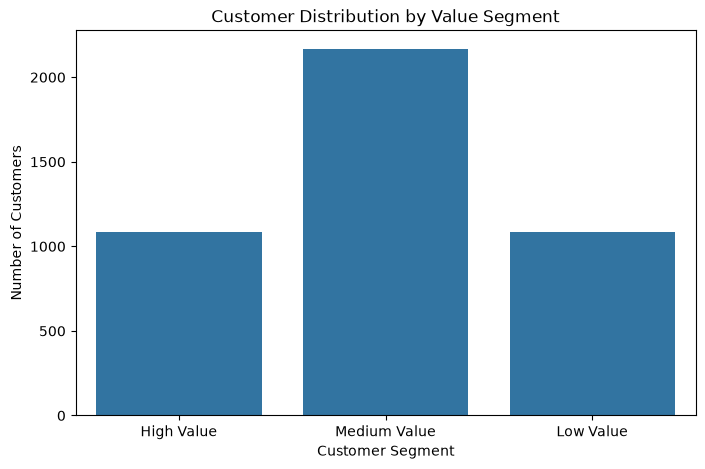

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=clv,
    x="Value_Segment",
    order=["High Value", "Medium Value", "Low Value"]
)

plt.title("Customer Distribution by Value Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.show()

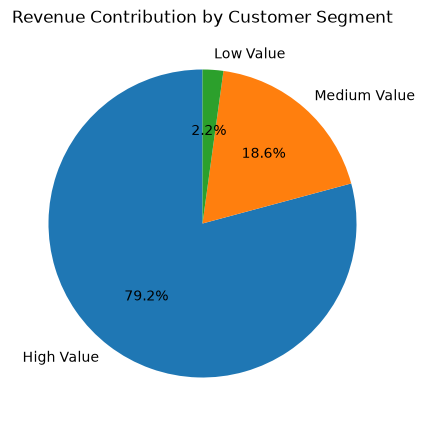

In [65]:
plt.figure(figsize=(8, 5))

segment_revenue = clv.groupby("Value_Segment")[
    "Customer_Lifetime_Value"
].sum()

segment_revenue = segment_revenue.reindex(
    ["High Value", "Medium Value", "Low Value"]
)

plt.pie(
    segment_revenue,
    labels=segment_revenue.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Contribution by Customer Segment")
plt.show()

In [66]:
!pip install plotly

In [67]:
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

In [68]:
total_revenue = df_clean["Revenue"].sum()
total_customers = df_clean["CustomerID"].nunique()
total_orders = df_clean["InvoiceNo"].nunique()
total_products = df_clean["StockCode"].nunique()

print("========== BUSINESS OVERVIEW ==========")
print("Total Revenue: £", round(total_revenue, 2))
print("Total Customers:", total_customers)
print("Total Orders:", total_orders)
print("Total Products:", total_products)

========== BUSINESS OVERVIEW ==========
Total Revenue: £ 8887208.89
Total Customers: 4338
Total Orders: 18532
Total Products: 3665


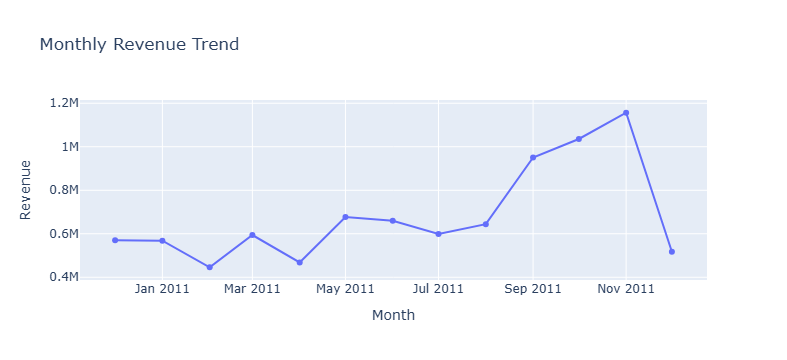

In [69]:
monthly_revenue = (
    df_clean.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

fig = px.line(
    monthly_revenue,
    x="Month",
    y="Revenue",
    title="Monthly Revenue Trend",
    markers=True
)

fig.show()

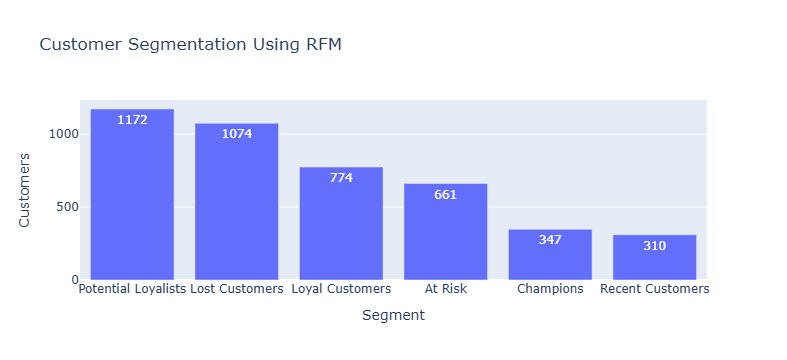

In [70]:
rfm_counts = rfm["Segment"].value_counts().reset_index()

rfm_counts.columns = ["Segment", "Customers"]

fig = px.bar(
    rfm_counts,
    x="Segment",
    y="Customers",
    title="Customer Segmentation Using RFM",
    text="Customers"
)

fig.show()

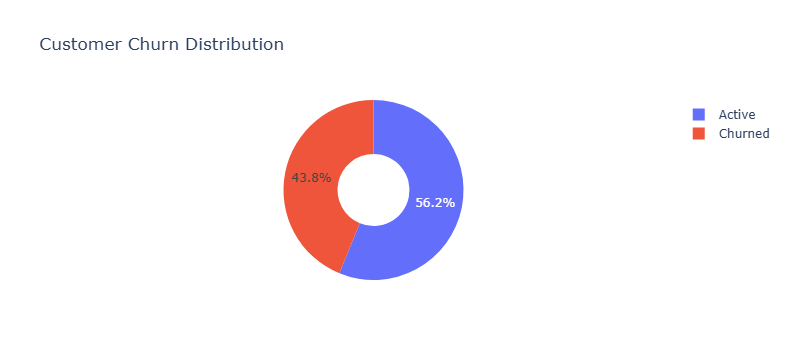

In [71]:
churn_counts = customer_features["Churn"].value_counts().reset_index()

churn_counts.columns = ["Churn", "Customers"]

churn_counts["Customer Status"] = churn_counts["Churn"].map({
    0: "Active",
    1: "Churned"
})

fig = px.pie(
    churn_counts,
    names="Customer Status",
    values="Customers",
    title="Customer Churn Distribution",
    hole=0.4
)

fig.show()

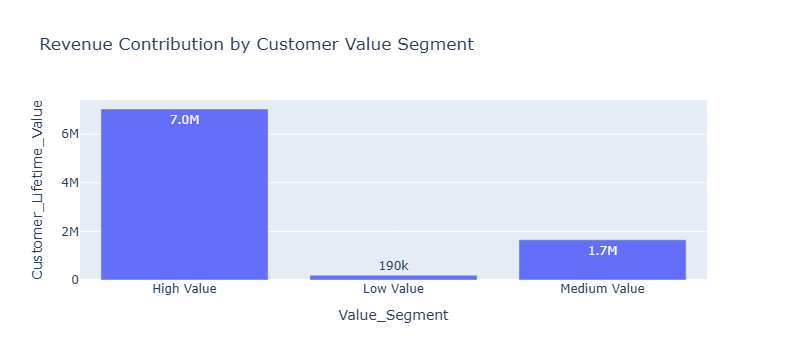

In [72]:
segment_revenue = (
    clv.groupby("Value_Segment")["Customer_Lifetime_Value"]
    .sum()
    .reset_index()
)

fig = px.bar(
    segment_revenue,
    x="Value_Segment",
    y="Customer_Lifetime_Value",
    title="Revenue Contribution by Customer Value Segment",
    text_auto=".2s"
)

fig.show()

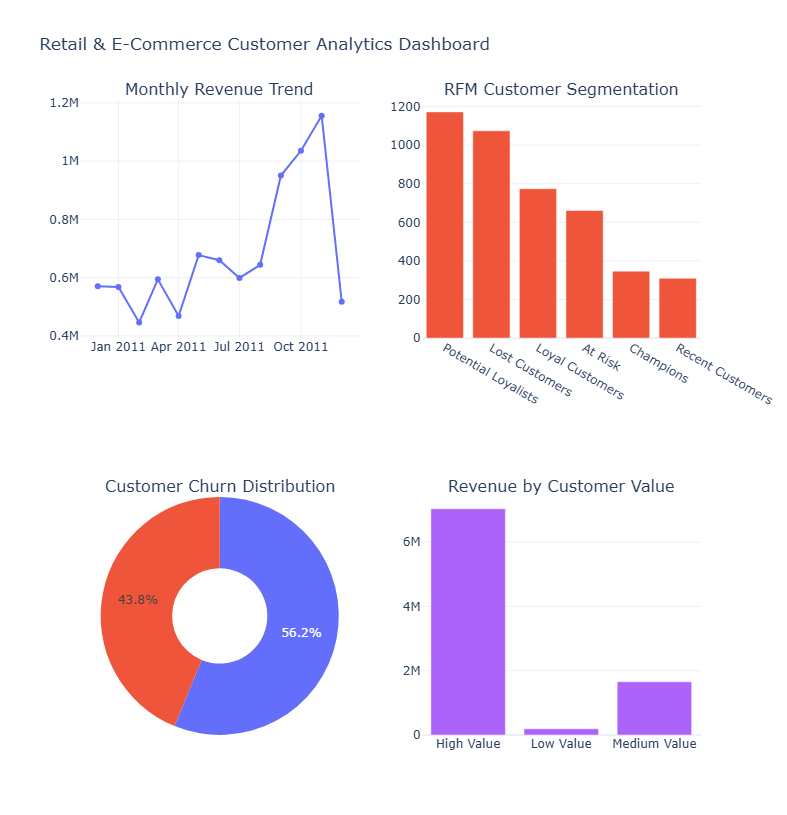

Dashboard saved successfully!


In [74]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

# Prepare chart data
monthly_revenue = (
    df_clean.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

rfm_counts = rfm["Segment"].value_counts()

churn_counts = customer_features["Churn"].value_counts()

clv_revenue = clv.groupby("Value_Segment")[
    "Customer_Lifetime_Value"
].sum()

# Create dashboard layout
fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Monthly Revenue Trend",
        "RFM Customer Segmentation",
        "Customer Churn Distribution",
        "Revenue by Customer Value"
    ),
    specs=[
        [{"type": "scatter"}, {"type": "bar"}],
        [{"type": "domain"}, {"type": "bar"}]
    ]
)

# Chart 1: Monthly revenue
fig.add_trace(
    go.Scatter(
        x=monthly_revenue["Month"],
        y=monthly_revenue["Revenue"],
        mode="lines+markers",
        name="Monthly Revenue"
    ),
    row=1, col=1
)

# Chart 2: RFM segmentation
fig.add_trace(
    go.Bar(
        x=rfm_counts.index,
        y=rfm_counts.values,
        name="Customers"
    ),
    row=1, col=2
)

# Chart 3: Churn distribution
fig.add_trace(
    go.Pie(
        labels=["Active", "Churned"],
        values=[
            churn_counts.get(0, 0),
            churn_counts.get(1, 0)
        ],
        hole=0.4,
        name="Churn"
    ),
    row=2, col=1
)

# Chart 4: CLV revenue contribution
fig.add_trace(
    go.Bar(
        x=clv_revenue.index,
        y=clv_revenue.values,
        name="Revenue"
    ),
    row=2, col=2
)

# Dashboard title and dimensions
fig.update_layout(
    title_text="Retail & E-Commerce Customer Analytics Dashboard",
    height=800,
    width=1200,
    showlegend=False,
    template="plotly_white"
)

fig.show()
fig.write_html("Retail_Customer_Analytics_Dashboard.html")

print("Dashboard saved successfully!")

In [75]:
import os
print(os.getcwd())

C:\Users\saksh\Downloads\Retail_Churn_Analytics\notebooks


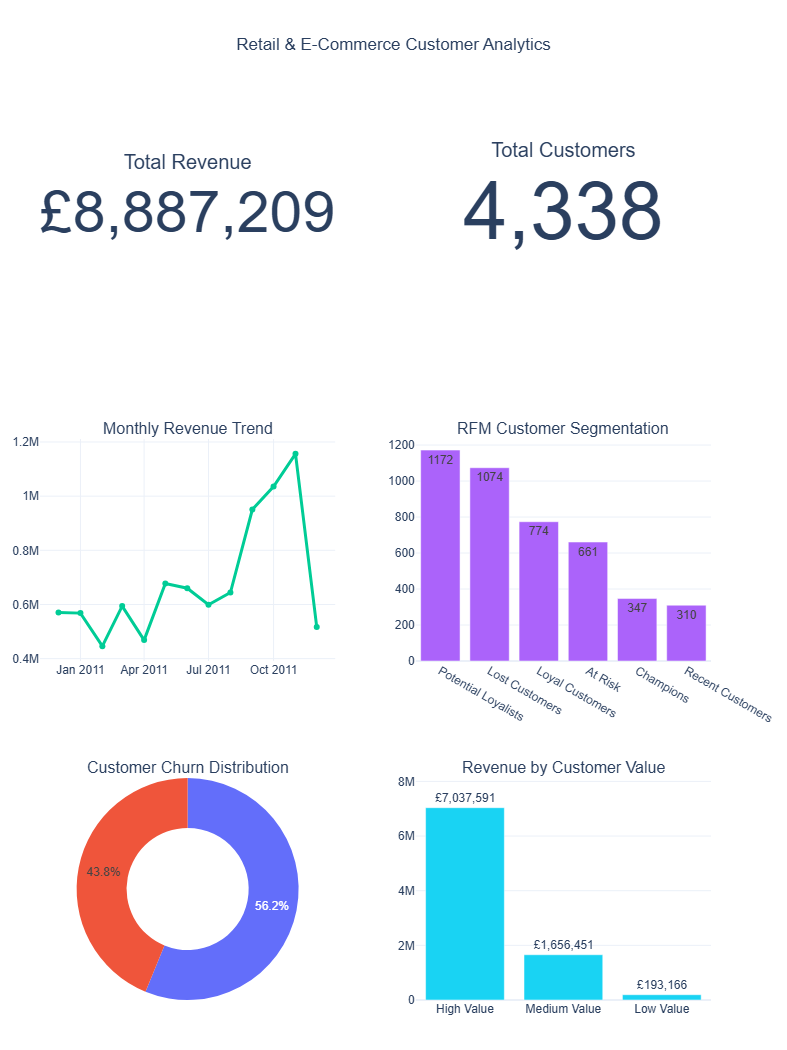

Responsive dashboard saved successfully!


In [76]:

from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

# -------------------------------
# 1. Prepare dashboard data
# -------------------------------

monthly_revenue = (
    df_clean.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

rfm_counts = rfm["Segment"].value_counts()

churn_counts = customer_features["Churn"].value_counts()

clv_revenue = (
    clv.groupby("Value_Segment")["Customer_Lifetime_Value"]
    .sum()
    .reindex(["High Value", "Medium Value", "Low Value"])
)

# KPI values
total_revenue = df_clean["Revenue"].sum()
total_customers = df_clean["CustomerID"].nunique()
total_orders = df_clean["InvoiceNo"].nunique()
total_products = df_clean["StockCode"].nunique()

# -------------------------------
# 2. Create responsive dashboard
# -------------------------------

fig = make_subplots(
    rows=3,
    cols=2,
    specs=[
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "scatter"}, {"type": "bar"}],
        [{"type": "domain"}, {"type": "bar"}]
    ],
    subplot_titles=(
        "", "",
        "Monthly Revenue Trend",
        "RFM Customer Segmentation",
        "Customer Churn Distribution",
        "Revenue by Customer Value"
    ),
    vertical_spacing=0.13,
    horizontal_spacing=0.12
)

# -------------------------------
# 3. KPI cards
# -------------------------------

fig.add_trace(
    go.Indicator(
        mode="number",
        value=total_revenue,
        number={"prefix": "£", "valueformat": ",.0f"},
        title={"text": "Total Revenue"}
    ),
    row=1, col=1
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=total_customers,
        number={"valueformat": ",.0f"},
        title={"text": "Total Customers"}
    ),
    row=1, col=2
)

# -------------------------------
# 4. Monthly revenue chart
# -------------------------------

fig.add_trace(
    go.Scatter(
        x=monthly_revenue["Month"].astype(str),
        y=monthly_revenue["Revenue"],
        mode="lines+markers",
        name="Monthly Revenue",
        line=dict(width=3),
        hovertemplate="Month: %{x}<br>Revenue: £%{y:,.2f}<extra></extra>"
    ),
    row=2, col=1
)

# -------------------------------
# 5. RFM segmentation chart
# -------------------------------

fig.add_trace(
    go.Bar(
        x=rfm_counts.index,
        y=rfm_counts.values,
        name="Customers",
        text=rfm_counts.values,
        textposition="auto",
        hovertemplate="%{x}<br>Customers: %{y}<extra></extra>"
    ),
    row=2, col=2
)

# -------------------------------
# 6. Churn chart
# -------------------------------

fig.add_trace(
    go.Pie(
        labels=["Active", "Churned"],
        values=[
            churn_counts.get(0, 0),
            churn_counts.get(1, 0)
        ],
        hole=0.55,
        hovertemplate="%{label}: %{value}<br>%{percent}<extra></extra>"
    ),
    row=3, col=1
)

# -------------------------------
# 7. Customer value chart
# -------------------------------

fig.add_trace(
    go.Bar(
        x=clv_revenue.index,
        y=clv_revenue.values,
        name="Revenue",
        text=clv_revenue.values,
        texttemplate="£%{y:,.0f}",
        textposition="outside",
        hovertemplate="%{x}<br>Revenue: £%{y:,.2f}<extra></extra>"
    ),
    row=3, col=2
)

# -------------------------------
# 8. Dashboard styling
# -------------------------------

fig.update_layout(
    title={
        "text": "Retail & E-Commerce Customer Analytics",
        "x": 0.5,
        "xanchor": "center"
    },
    template="plotly_white",
    height=1050,
    autosize=True,
    margin=dict(l=35, r=35, t=100, b=50),
    font=dict(family="Arial", size=12),
    showlegend=False,
    hoverlabel=dict(font_size=13)
)

fig.update_xaxes(automargin=True)
fig.update_yaxes(automargin=True)

# -------------------------------
# 9. Display dashboard
# -------------------------------

fig.show(config={
    "responsive": True,
    "displayModeBar": True,
    "scrollZoom": True
})

# Save updated dashboard
fig.write_html(
    "Retail_Customer_Analytics_Dashboard.html",
    config={"responsive": True}
)

print("Responsive dashboard saved successfully!")
